# III. Fundamentos del Modelamiento Predictivo
# Capítulo 8 - Modelos de Clasificación (Ejercicios)

<div style="border-top: 20px solid #b6effb; border-bottom: 20px solid #b6effb; background-color: #cff4fc; color: #055160;">

En los siguientes ejercicios se busca dar respuesta una pregunta muy usual que surge al momento de desarrollar un modelo predictivo: ¿Cuánto es un nivel de asertividad suficientemente alto para considerar a dicho modelo como adecuado? Si bien no existen valores de exactitud, precisión o sensibilidad puntuales que nos permitan contestar directamente esta interrogante puesto que muchas veces los mismos dependen del contexto del caso estudiado, es posible establecer los denominados **criterios de cordura**, los cuales, mediante una lógica técnica aproximan una valoración sobre la calidad predictiva del modelo en lo referente a los datos observados.

En concreto, nos enfocaremos en dos **criterios de cordura** muy utilizados en la ciencia de datos actual:

* **Métricas de modelo dummy**: Aquí nos enfocamos en construir un modelo de línea base (*dummy*) que sustente sus pronósticos únicamente en la realidad observada de la variable objetivo, y a partir de allí calcular métricas de rendimiento mínimas esperadas para cualquier otro modelo que utilice técnicas más avanzadas. Si este último tiene mejores resultados entonces se puede concluir que funciona mejor que la aleatoriedad más básica dada la información disponible.

* **Estimación del lift versus modelo dummy**: En este punto damos una valoración concreta asociada al mejoramiento (o *lift*) del modelo con técnicas más avanzadas respecto a uno *dummy*, calculando para esto las "veces" que se incrementa la capacidad predictiva respecto a la aleatoriedad.

Vale reiterar que en cualquier contexto, siempre habrá que considerar también como **criterio de cordura** la realidad en la que se implementaría un modelo predictivo. Así por ejemplo, no es lo mismo una exactitud del 90.0% en la determinación de posibles fraudes financieros, que este mismo porcentaje en la estimación de enfermedades.

</div>

## Entendimiento de los datos

### Ejercicio 1

Importa las librerías **pandas**, **numpy**, **matplotlib**, junto con la clase `LogisticRegression` del módulo `linear_model` de **scikit-learn**, y `metrics` de esta misma librería. 

In [1]:
# Cargar librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

En estos ejercicios trabajaremos con información asociada al registro climático durante un mes en una ciudad. Para cargar los datos ejecuta el siguiente código:

```py
df_weather = pd.DataFrame(dict(
    temperature = [
        10,14,9,18,18,10,21,16,18,14,
        11,16,16,25,27,21,15,11,16,24,
        23,25,26,25,24,25,20,17,15,14
    ],
    rain = [
        "Yes","Yes","Yes","No","No","Yes","No","No","No","Yes",
        "Yes","No","Yes","No","No","No","No","Yes","Yes","No",
        "No","No","No","No","Yes","No","No","No","Yes","No"
    ]
), index = range(1,31))
df_weather.index.name = "dia"
```

In [2]:
df_weather = pd.DataFrame(dict(
    temperature = [
        10,14,9,18,18,10,21,16,18,14,
        11,16,16,25,27,21,15,11,16,24,
        23,25,26,25,24,25,20,17,15,14
    ],
    rain = [
        "Yes","Yes","Yes","No","No","Yes","No","No","No","Yes",
        "Yes","No","Yes","No","No","No","No","Yes","Yes","No",
        "No","No","No","No","Yes","No","No","No","Yes","No"
    ]
), index = range(1,31))
df_weather.index.name = "dia"

Mira la estructura de la tabla creada.

In [3]:
df_weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 1 to 30
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   temperature  30 non-null     int64 
 1   rain         30 non-null     object
dtypes: int64(1), object(1)
memory usage: 612.0+ bytes


### Ejercicio 2

Este dataset contiene datos de la temperatura en grados Celsius promedio registrada durante cada uno de los días del mes, así como si en dicho día se presentaron frentes de lluvia. Explora la información aquí contenida.

In [4]:
# Generar muestra de los datos
df_weather.sample(10)

,temperature,rain
dia,,
4,18,No
24,25,No
16,21,No
30,14,No
6,10,Yes
26,25,No
14,25,No
10,14,Yes
3,9,Yes


In [5]:
# Generar un resumen estadistico de temperature
df_weather["temperature"].describe().round(2)

count    30.00
mean     18.13
std       5.41
min       9.00
25%      14.25
50%      17.50
75%      23.75
max      27.00
Name: temperature, dtype: float64

In [6]:
# Mirar casos por clase de rain
df_weather["rain"].value_counts()

rain
No     19
Yes    11
Name: count, dtype: int64

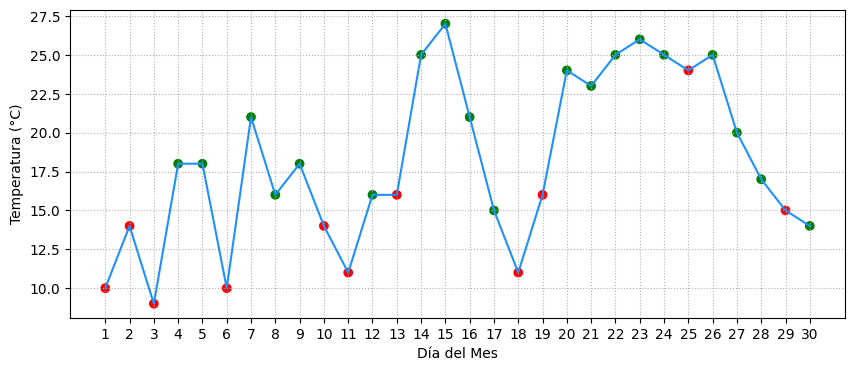

In [7]:
# Visualizar comportamiento de las variables a través de los dias
plt.figure(figsize = [10,4])

plt.plot(
    df_weather.index,
    df_weather["temperature"],
    color = "dodgerblue"
)

plt.scatter(
    x = df_weather.index,
    y = df_weather["temperature"],
    c = ["red" if x == "Yes" else "green" for x in df_weather["rain"]],
    marker = "o"
)

plt.xlabel("Día del Mes")
plt.ylabel("Temperatura (°C)")
plt.xticks(df_weather.index)
plt.grid(linestyle = ":")
plt.show()

Observa ahora el siguiente Objetivo Técnico y el algoritmo y métricas a utilizar para que tengas claro lo que queremos modelar en las próximas secciones.

<div class="alert alert-success">

**OBJETIVO TÉCNICO**

Pronosticar con alta asertividad la variable objetivo rain a partir de atributo temperature. Para esto, se debe crear un modelo supervisado de clasificación que permita predecir si en un día cualquiera del mes se presentará lluvia ("Yes") o no.

</div>

<div class="alert alert-success">

**ALGORITMO Y METRICAS DE RENDIMIENTO**

* *Algoritmo:* Regresión Logística.
* *Métricas de rendimiento*: Exactitud, F1 de la clase "Yes".

</div>

## Creación de modelo con regresión logística

### Ejercicio 1

Divide el dataset en sus componentes de atributo y variable objetivo.

In [8]:
X = df_weather.drop(columns = "rain")
y = df_weather["rain"]

Crea y entrena un modelo con el algoritmo de regresión logistica capaz de pronosticar la variable objetivo a través del atributo temperature. Recuerda utilizar los argumentos `solver = "liblinear"`, `max_iter = 100` y `random_state = 123`.

In [9]:
# Crear modelo con Regresion Logistica
mod_rlog = LogisticRegression(
    solver = "liblinear",
    max_iter = 100,
    random_state = 123
)

In [10]:
# Entrenar modelo
mod_rlog.fit(X, y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",123
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mult

### Ejercicio 2

Calcula los valores predichos de la variable objetivo.

In [11]:
y_pred = mod_rlog.predict(X)

A partir de estos resultados construye una matriz de confusión para contrastar este pronóstico con los valores reales.

In [12]:
mat_conf = pd.crosstab(
    index = y,
    columns = y_pred,
    margins = True,
    rownames = ["Real"],
    colnames = ["Predicho"]
)
print(mat_conf)

Predicho  No  Yes  All
Real                  
No        19    0   19
Yes        6    5   11
All       25    5   30


Calcula y guarda las métricas de exactitud y f1 para el caso de lluvia.

In [13]:
acc_rlog = metrics.accuracy_score(y, y_pred)
f1_rlog = metrics.f1_score(y, y_pred, pos_label = "Yes")
print(f"Exactitud Modelo RLog: {acc_rlog:.1%}")
print(f"F1 para Yes Modelo RLog: {f1_rlog:.1%}")

Exactitud Modelo RLog: 80.0%
F1 para Yes Modelo RLog: 62.5%


¿Qué tan asertivo es este rendimiento alcanzado? Creemos en la siguiente sección un modelo *dummy* para contar con una referencia base de estas métricas.

## Métricas de modelo *dummy*

### Ejercicio 1

Un modelo *dummy* (o de línea base) es aquel que genera pronósticos de la variable objetivo únicamente a través de la información histórica asociada a la misma, y sin considerar ninguna información adicional (i.e atributos como la temperatura en el día). Para comprender de mejor manera su funcionamiento, empieza calculando la proporción de observaciones del dataset `df_weather` que corresponden a la clase rain == "Yes" y rain == "No". Guarda estos resultados en `p_real_y` y `p_real_n`,

In [14]:
p_real_y = np.mean(y == "Yes")
p_real_n = 1 - p_real_y

print(f"Proporcion real de Yes: {p_real_y:.1%}")
print(f"Proporcion real de No: {p_real_n:.1%}")

Proporcion real de Yes: 36.7%
Proporcion real de No: 63.3%


Supongamos ahora que nuestro modelo *dummy* usará como lógica de predicción el simple lanzamiento de una moneda "justa". Para cada una de las observaciones se ejecuta el experimento de lanzar la moneda en cuestión, y si sale cara se contará con una predicción de lluvia para ese día, y si sale cruz se concluirá que no llueve. Lo anterior implica que es esperable que se obtenga un $50\%$ de días lluviosos (y $(1-0.5)\times 100 \%$ de días sin este evento climático).

Guarda las proporciones correspondientes a este modelamiento en las variables `p_pred_y` y `p_pred_n`, respectivamente

In [15]:
p_pred_y = 0.5
p_pred_n = 1 - p_pred_y

print(f"Proporcion predicha de Yes: {p_pred_y:.1%}")
print(f"Proporcion predicha de No: {p_pred_n:.1%}")

Proporcion predicha de Yes: 50.0%
Proporcion predicha de No: 50.0%


### Ejercicio 2

Procedamos ahora a calcular las métricas de rendimiento de este modelo. Dadas las probabilidades antes generadas, estima la proporción de casos reales "Yes", que el modelo *dummy* será capaz de pronosticar correctamente. En otras palabras, calcula la Tasa de Reales Positivos ($TPR$) tal que

$$ TPR = P(Real = Yes) \times P(Pred = Yes) $$

In [16]:
tpr = p_real_y * p_pred_y
print(f"TPR: {tpr:.1%}")

TPR: 18.3%


Estima ahora la Tasa de Reales Negativos ($TNR$), esto es, la proporcion de casos reales "No" que el modelo *dummy* pronosticaría correctamente. Considera que

$$ TNR = P(Real = No) \times P(Pred = No) $$

In [17]:
tnr = p_real_n * p_pred_n
print(f"TNR: {tnr:.1%}")

TNR: 31.7%


Si lo piensas detenidamente, se cumple que

$$ Exactitud = TPR + TNR $$

Por tanto, determina la exactitud del modelo *dummy* y guarda este resultado en `acc`.

In [18]:
acc = tpr + tnr
print(f"Exactitud: {acc:.1%}")

Exactitud: 50.0%


En la misma línea, se cumple también que

$$ Precision_{yes} = \frac{TPR}{P(Pred = Yes)} $$

$$ Recall_{yes} = \frac{TPR}{P(Real = Yes)} $$

Dado que la métrica F1 consiste en la **media armónica** de estos indicadores, calcula su valor para el caso del modelo *dummy*, y guarda su resultado en la variable `f1_y`. 

In [19]:
prec_y = tpr / p_pred_y
rec_y = tpr / p_real_y
f1_y = 2 * prec_y * rec_y / (prec_y + rec_y)
print(f"F1 para Yes: {f1_y:.1%}")

F1 para Yes: 42.3%


En conclusión, visto que con un modelo *dummy* basado en el lanzamiento de una moneda la exactitud y F1 alcanzan $50.0\%$ y $42.3\%$ respectivamente, podríamos inferir que el modelo de *regresión logística* antes empleado tiene un mejor rendimiento que la lógica aleatoria simple. 

### Ejercicio 3

A partir de la lógica antes expuesta, creemos un modelo *dummy* más acorde al contexto y los datos con los que estamos trabajando. Para ello define la función `fun_dummy` que reciba como entrada una proporción cualquiera `p_pred_y`, y que corresponda a la probabilidad que deseamos utilizar como pronóstico de lluvia. Esta función debería devolver los valores de exactitud y F1 asociados, y siguiendo el procedimiento visto en el ejercicio anterior.

In [20]:
def fun_dummy (p_pred_y):

    # Obtener proporciones reales de cada clase
    p_real_y = np.mean(df_weather["rain"] == "Yes")
    p_real_n = 1 - p_real_y

    # Definir proporciones predichas de cada clase 
    p_pred_n = 1 - p_pred_y

    # Calcular tpr y tnr
    tpr = p_real_y * p_pred_y
    tnr = p_real_n * p_pred_n

    # Calcular metricas de rendimiento
    acc = tpr + tnr
    if p_pred_y > 0:
        prec_y = tpr / p_pred_y
        rec_y = tpr / p_real_y
        f1_y = 2 * prec_y * rec_y / (prec_y + rec_y)
    else:
        f1_y = 0

    return acc, f1_y

Comprueba tu función con una entrada de 0.5. El resultado debería corresponder a lo calculado antes.

In [21]:
acc, f1_y = fun_dummy(0.5)
print(f"Exactitud: {acc:.1%}")
print(f"F1 para Yes: {f1_y:.1%}")

Exactitud: 50.0%
F1 para Yes: 42.3%


Utilizando la función, extrae en listas separadas los distintos resultados de exactitud y F1 que se generarían ante distintas proporciones de entrada. 

In [22]:
prop_opt = np.array(range(0,101,5))/100

acc_result = []
f1_result = []

for p in prop_opt:
    acc_p, f1_p = fun_dummy(p)
    acc_result.append(acc_p)
    f1_result.append(f1_p)

Visualiza el comportamiento entre las diferentes exactitudes y valores de F1 generados por distintas proporciones de entrada.

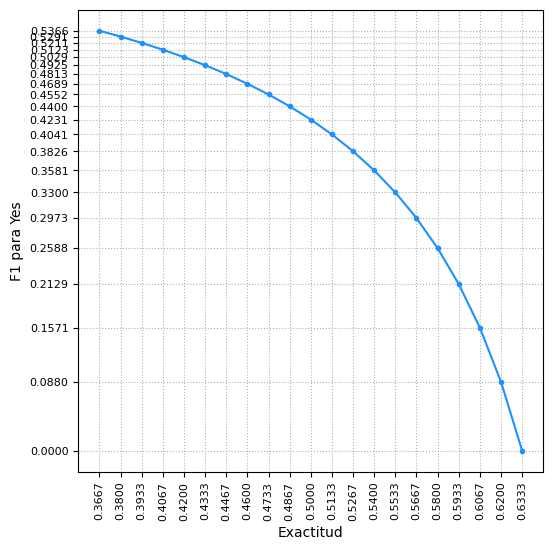

In [23]:
plt.figure(figsize = [6,6])
plt.plot(
    acc_result, f1_result,
    color = "dodgerblue",
    marker = "."
)

plt.xlabel("Exactitud")
plt.xticks(acc_result, rotation = 90, fontsize = 8)
plt.ylabel("F1 para Yes")
plt.yticks(f1_result, fontsize = 8)
plt.grid(linestyle = ":")
plt.show()

Si todo ha sido realizado correctamente, notarás que se genera una curva con un potencial punto codal que optimiza el *trade off* entre ambas métricas. No vamos a entrar en detalle, pero este óptimo se alcanza cuando la proporción pronosticada de lluvia se corresponde con la proporción real observada en los datos tal que

$$ P(Pred = Yes) = P(Real = Yes) $$

Utiliza entonces esta condición para encontrar el rendimiento de este modelo *dummy* óptimo. guarda las métricas alcanzadas en `acc_best` y `f1_best`. 

In [24]:
acc_best, f1_best = fun_dummy(p_real_y)
print(f"Exactitud Modelo Dummy: {acc_best:.1%}")
print(f"F1 para Yes Modelo Dummy: {f1_best:.1%}")

Exactitud Modelo Dummy: 53.6%
F1 para Yes Modelo Dummy: 36.7%


Este resultado da cuenta que nuestro modelo con *regresión logística* igualmente tiene un rendimiento superior que la lógica aleatoria basada en información histórica.

Finaliza esta sección generando una tabla resumen que contraste ambas métricas para los 3 modelos vistos.

In [25]:
res_metricas = pd.DataFrame(dict(
    accuracy = [acc, acc_best, acc_rlog],
    f1_score = [f1_y, f1_best, f1_rlog] 
), index = ["Dummy Sim.", "Dummy Opt.", "Reg. Log."])

print(res_metricas.round(3))

            accuracy  f1_score
Dummy Sim.     0.500     0.423
Dummy Opt.     0.536     0.367
Reg. Log.      0.800     0.625


<div class="alert alert-info">

El modelo *dummy* optimizado que creamos se llama específicamente **dummy estratificado**. Para formalizar las métricas asociadas a este modelo de línea base, a continuación se presentan las fórmulas de las mismas:

$$ Exactitud = \sum_{i=1}^{K}p_i^2 $$

$$ F1_k = Precision_k = Recall_k = p_k $$

donde $K$ corresponde a la cantidad de clases de la variable objetivo, $k$ a una clase en específico, y $p_k$ a su correspondiente proporción en el total de observaciones.

**Scikit-Learn** cuenta ya con este algoritmo, y para implementarlo puedes utilizar el siguiente código:

```py
from sklearn.dummy import DummyClassifier

mod_dummy = DummyClassifier(strategy = "stratified")
```

Si es de tu interés, aquí encontrarás la <a href="https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html">documentación</a> de esta clase `DummyClassifier`.

</div>

## Estimación de Lift de modelo

### Ejercicio 1

En este apartado nos enfocaremos en cuantificar de manera definitiva qué tanto es mejor nuestro modelo de *regresión logística* en relación al *dummy* óptimo. Para ello vamos a calcular el indicador conocido como **lift** que mide "las veces" en que un modelo es mejor a otro en lo referente a su capacidad predictiva.

Como punto de partida, obtén las probabilidades predichas por el modelo de regresión logística para la clase de lluvia "Yes". Utiliza el método `predict_proba` y guarda estos resultados en `y_pred_p`.

In [26]:
y_pred_p = mod_rlog.predict_proba(X)[:,1]
y_pred_p

array([0.55028056, 0.42115647, 0.58218812, 0.30198571, 0.30198571,
       0.55028056, 0.22657829, 0.35940586, 0.30198571, 0.42115647,
       0.51795385, 0.35940586, 0.35940586, 0.14835446, 0.11841959,
       0.22657829, 0.38983977, 0.51795385, 0.35940586, 0.16553502,
       0.18427472, 0.14835446, 0.13267353, 0.14835446, 0.16553502,
       0.14835446, 0.25015685, 0.33006262, 0.38983977, 0.42115647])

Estima ahora los 9 deciles asociados a estas probabilidades mediante la función `np.quantile`. guarda los resultados en `dec_p`.

In [27]:
dec_p = np.quantile(y_pred_p, q = np.array(range(1,10))/10)
dec_p

array([0.14835446, 0.16209891, 0.21388722, 0.28125417, 0.31602417,
       0.35940586, 0.38983977, 0.42115647, 0.52118652])

Crea un arreglo que contenga los grupos de deciles a los cuales se corresponde cada una de las observaciones. Para ello ejecuta el siguiente código:

```py
dec_group = np.searchsorted(dec_p, y_pred_p, side = "right") + 1
dec_group
```

In [28]:
dec_group = np.searchsorted(dec_p, y_pred_p, side = "right") + 1
dec_group

array([10,  9, 10,  5,  5, 10,  4,  7,  5,  9,  9,  7,  7,  2,  1,  4,  8,
        9,  7,  3,  3,  2,  1,  2,  3,  2,  4,  6,  8,  9])

### Ejercicio 2

Crea una copia del dataset `df_weather` y adiciona allí una columna *decile_group* que contenga la información contenida en `dec_group`.

In [29]:
df_weather_c = df_weather.copy()
df_weather_c["decile_group"] = dec_group
df_weather_c.sample(5)

,temperature,rain,decile_group
dia,,,
4,18,No,5
14,25,No,2
3,9,Yes,10
19,16,Yes,7
8,16,No,7


Para facilitar cálculos posteriores en este nuevo dataset modifica la columna rain tal que "Yes" se transforme a 1 y "No" a 0.

In [30]:
df_weather_c["rain"] = df_weather_c["rain"].apply(lambda x: 1 if x == "Yes" else 0)
df_weather_c.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 1 to 30
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   temperature   30 non-null     int64
 1   rain          30 non-null     int64
 2   decile_group  30 non-null     int64
dtypes: int64(3)
memory usage: 852.0 bytes


Con esta información construye un dataframe `df_lift` donde se cuente tanto las observaciones totales de cada grupo de decil, como las observaciones de lluvia. 

In [31]:
df_lift = (
    df_weather_c
    .groupby("decile_group")
    .agg(
        q_total = ("rain","count"), 
        q_yes = ("rain", "sum")
    )
)
df_lift

,q_total,q_yes
decile_group,,
1,2,0
2,4,0
3,3,1
4,3,0
5,3,0
6,1,0
7,4,2
8,2,1
9,5,4


Esta es la base para calcular el **lift** de nuestro modelo con *regresión logística*. Para entenderlo conceptualmente piensa en lo siguiente: nota que el grupo de decil 1 representa los casos en los que el modelo estimó las probabilidades más bajas de lluvia, mientras que el grupo 10 muestra por el contrario aquellas observaciones con un mejor pronóstico probabilístico. En otras palabras, en caso de existir lluvia en alguna observación del grupo 1, la capacidad predictiva del modelo aquí es la peor, mientras que la capacidad en el otro grupo es la mejor.

Llevemos a números más concretos estas afirmaciones en el siguiente ejercicio.

### Ejercicio 3

Mediante un reordenamiento descendente de los índices y el método `cumsum`, crea columnas en `df_lift` que muestren los conteos agregados "inversos" de la cantidad de casos totales y de aquellos que representan lluvia.

In [32]:
df_lift = df_lift.sort_index(ascending = False)
df_lift["cum_total"] = df_lift["q_total"].cumsum()
df_lift["cum_yes"] = df_lift["q_yes"].cumsum()
df_lift

,q_total,q_yes,cum_total,cum_yes
decile_group,,,,
10,3,3,3,3
9,5,4,8,7
8,2,1,10,8
7,4,2,14,10
6,1,0,15,10
5,3,0,18,10
4,3,0,21,10
3,3,1,24,11
2,4,0,28,11


Si lo hiciste correctamente verás que en las nuevas columnas creadas con los conteos acumulados, los valores correspondientes al grupo de decil 1 se corresponden exactamente con las filas del dataset `df_weather` (30) y el total de observaciones positivas en él (11).

Justamente en esta fila se guarda la capacidad predictiva de un modelo *dummy*, pues el mismo utilizaría como referencia la proporción dada por $11/30 \approx 0.367$. Para verificarlo, calcula en una nueva columna esta proporción para todos los grupos dividiendo los conteos acumulados que correspondan.

In [33]:
df_lift["p_cum_yes"] = df_lift["cum_yes"] / df_lift["cum_total"]
df_lift

,q_total,q_yes,cum_total,cum_yes,p_cum_yes
decile_group,,,,,
10,3,3,3,3,1.000000
9,5,4,8,7,0.875000
8,2,1,10,8,0.800000
7,4,2,14,10,0.714286
6,1,0,15,10,0.666667
5,3,0,18,10,0.555556
4,3,0,21,10,0.476190
3,3,1,24,11,0.458333
2,4,0,28,11,0.392857


Visto esto, divide cada una de estas proporciones por la proporción asociada al modelo *dummy*, es decir, por la proporción más baja encontrada. Llama a esta columna *lift*.

In [34]:
df_lift["lift"] = df_lift["p_cum_yes"] / df_lift["p_cum_yes"].min()
df_lift

,q_total,q_yes,cum_total,cum_yes,p_cum_yes,lift
decile_group,,,,,,
10,3,3,3,3,1.000000,2.727273
9,5,4,8,7,0.875000,2.386364
8,2,1,10,8,0.800000,2.181818
7,4,2,14,10,0.714286,1.948052
6,1,0,15,10,0.666667,1.818182
5,3,0,18,10,0.555556,1.515152
4,3,0,21,10,0.476190,1.298701
3,3,1,24,11,0.458333,1.250000
2,4,0,28,11,0.392857,1.071429


Visualiza el comportamiento de este *lift* con relación a los deciles. La curva resultante se denomina justamente **curva lift**.

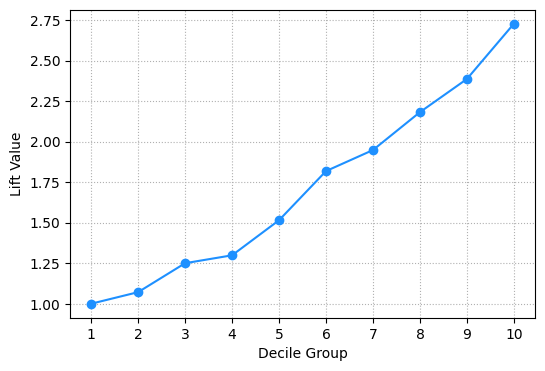

In [35]:
df_lift.plot(
    y = "lift",
    figsize = [6,4],
    legend = None,
    marker = "o",
    ylabel = "Lift Value",
    xlabel = "Decile Group",
    color = "dodgerblue"
)

plt.xticks(df_lift.index)
plt.grid(linestyle = ":")
plt.show()

Como mencionamos líneas atrás, el grupo 10 representa el mejor rendimiento potencial del modelo con *regresión logística*, y justamente aquí se alcanza el mejor valor de *lift*. Extrae este indicador y muéstralo en pantalla.

In [36]:
lift_total = df_lift["lift"].max()
print(f"Lift del Modelo RLog: {lift_total:.2f} veces")

Lift del Modelo RLog: 2.73 veces


Se puede entonces afirmar que el modelo con técnicas avanzadas que hemos desarrollado es 2.73 veces mejor en términos de asertividad que uno de tipo *dummy*.

<div class="alert alert-info">

Otras curvas derivadas de este cálculo y que permiten extraer métricas útiles para la evaluación de modelos mediante **criterios de cordura** son las siguientes:

* **Curva de Ganancia**: Presenta la proporción acumulada de observaciones positivas respecto al grupo de deciles. A partir de aquí se puede obtener el ya conocido *Índice de Gini*.

* **Curva CAP (Cumulative Accuracy Profile)**: Muestra el valor de exactitud acumulado en cada grupo de deciles y permite calcular la denominada *Razón de Exactitud*.

* **Curva KSS (Kolmogorov-Smirnov Separation)**: Presenta en el mismo eje las proporciones acumuladas de observaciones positivas y negativas. La distancia máxima entre estas dos curvas se denomina *Estadístico KS*.

Te recomiendo investigar cómo se interpretan estos estadísticos en este contexto.

</div>